In [25]:
# importing libraries:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully ")

Libraries imported successfully 


In [26]:
df  = pd.read_csv (r"C:\Users\taman\Downloads\CDS project files.csv\HealthCareAnalytics.csv")

## step 2 : data overview and quality check 

In [27]:
dtype={"Stay": "string"}
print("Rows and columns:",df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isna().sum())
print("\nExact duplicate rows:",df.duplicated().sum())
display(df.head)

Rows and columns: (318438, 18)

Data types:
case_id                                int64
Hospital_code                          int64
Hospital_type_code                    object
City_Code_Hospital                     int64
Hospital_region_code                  object
Available_Extra_Rooms_in_Hospital      int64
Department                            object
Ward_Type                             object
Ward_Facility_Code                    object
Bed_Grade                            float64
patientid                              int64
City_Code_Patient                    float64
Type_of_Admission                     object
Severity_of_Illness                   object
Visitors_with_Patient                  int64
Age                                   object
Admission_Deposit                      int64
Stay                                  object
dtype: object

Missing Values:
case_id                                 0
Hospital_code                           0
Hospital_type_code             

<bound method NDFrame.head of         case_id  Hospital_code Hospital_type_code  City_Code_Hospital  \
0             1              8                  c                   3   
1             2              2                  c                   5   
2             3             10                  e                   1   
3             4             26                  b                   2   
4             5             26                  b                   2   
...         ...            ...                ...                 ...   
318433   318434              6                  a                   6   
318434   318435             24                  a                   1   
318435   318436              7                  a                   4   
318436   318437             11                  b                   2   
318437   318438             19                  a                   7   

       Hospital_region_code  Available_Extra_Rooms_in_Hospital    Department  \
0            

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318438 entries, 0 to 318437
Data columns (total 18 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   case_id                            318438 non-null  int64  
 1   Hospital_code                      318438 non-null  int64  
 2   Hospital_type_code                 318438 non-null  object 
 3   City_Code_Hospital                 318438 non-null  int64  
 4   Hospital_region_code               318438 non-null  object 
 5   Available_Extra_Rooms_in_Hospital  318438 non-null  int64  
 6   Department                         318438 non-null  object 
 7   Ward_Type                          318438 non-null  object 
 8   Ward_Facility_Code                 318438 non-null  object 
 9   Bed_Grade                          318325 non-null  float64
 10  patientid                          318438 non-null  int64  
 11  City_Code_Patient                  3139

## Step 3 — Target identification
`Stay` is the target because it records the stay-duration range. Other columns are candidate inputs. Exclude `case_id` and `patientid` because they identify records or people rather than describe the stay.

In [29]:
target = "Stay"
identifier_columns = ["case_id", "patientid"]
feature_columns = [c for c in df.columns if c not in [target, *identifier_columns]]
print("Target:", target)
print("Stay categories and counts:")
print(df[target].value_counts(dropna=False))
print("\nNumber of categories:", df[target].nunique())
print("\nInput columns:", feature_columns)

Target: Stay
Stay categories and counts:
Stay
21-30                 87491
Nov-20                78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64

Number of categories: 11

Input columns: ['Hospital_code', 'Hospital_type_code', 'City_Code_Hospital', 'Hospital_region_code', 'Available_Extra_Rooms_in_Hospital', 'Department', 'Ward_Type', 'Ward_Facility_Code', 'Bed_Grade', 'City_Code_Patient', 'Type_of_Admission', 'Severity_of_Illness', 'Visitors_with_Patient', 'Age', 'Admission_Deposit']


## step 4: Exploratory Data Analysis (EDA)  

Feature summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hospital_code,318438.0,NaN,NaN,NaN,18.318841,8.633755,1.0,11.0,19.0,26.0,32.0
Hospital_type_code,318438,7,a,143425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City_Code_Hospital,318438.0,NaN,NaN,NaN,4.771717,3.102535,1.0,2.0,5.0,7.0,13.0
Hospital_region_code,318438,3,X,133336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Available_Extra_Rooms_in_Hospital,318438.0,NaN,NaN,NaN,3.197627,1.168171,0.0,2.0,3.0,4.0,24.0
Department,318438,5,gynecology,249486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ward_Type,318438,6,R,127947,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ward_Facility_Code,318438,6,F,112753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bed_Grade,318325.0,NaN,NaN,NaN,2.625807,0.873146,1.0,2.0,3.0,3.0,4.0
City_Code_Patient,313906.0,NaN,NaN,NaN,7.251859,4.745266,1.0,4.0,8.0,8.0,38.0


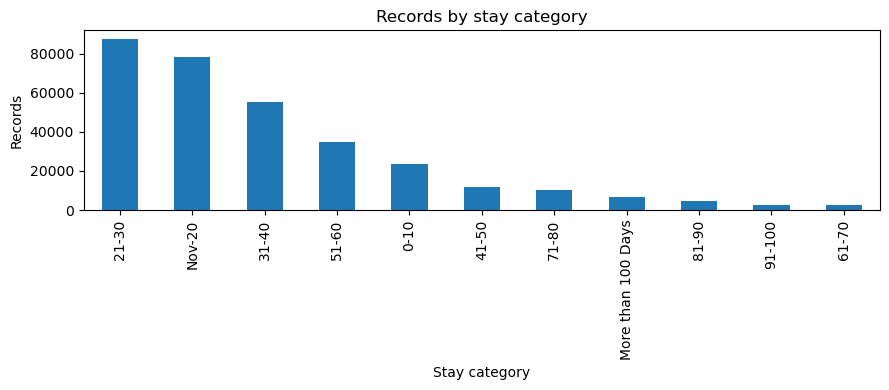

In [30]:
import matplotlib.pyplot as plt
print("Feature summary:")
display(df[feature_columns].describe(include="all").T)
ax = df[target].value_counts().plot(kind="bar", figsize=(9, 4), title="Records by stay category")
ax.set_xlabel("Stay category")
ax.set_ylabel("Records")
plt.tight_layout()
plt.show()

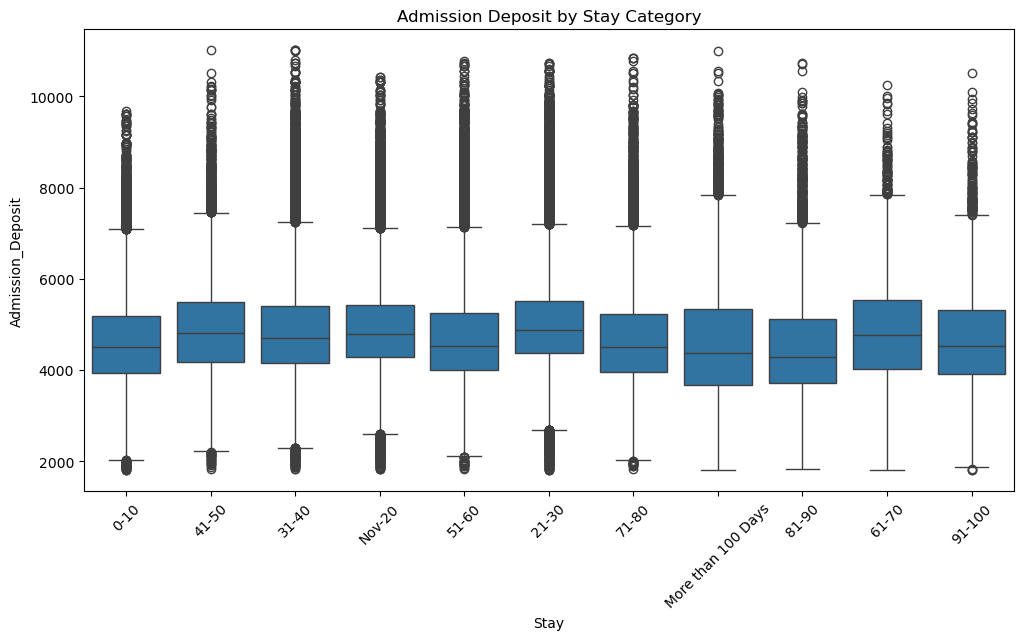

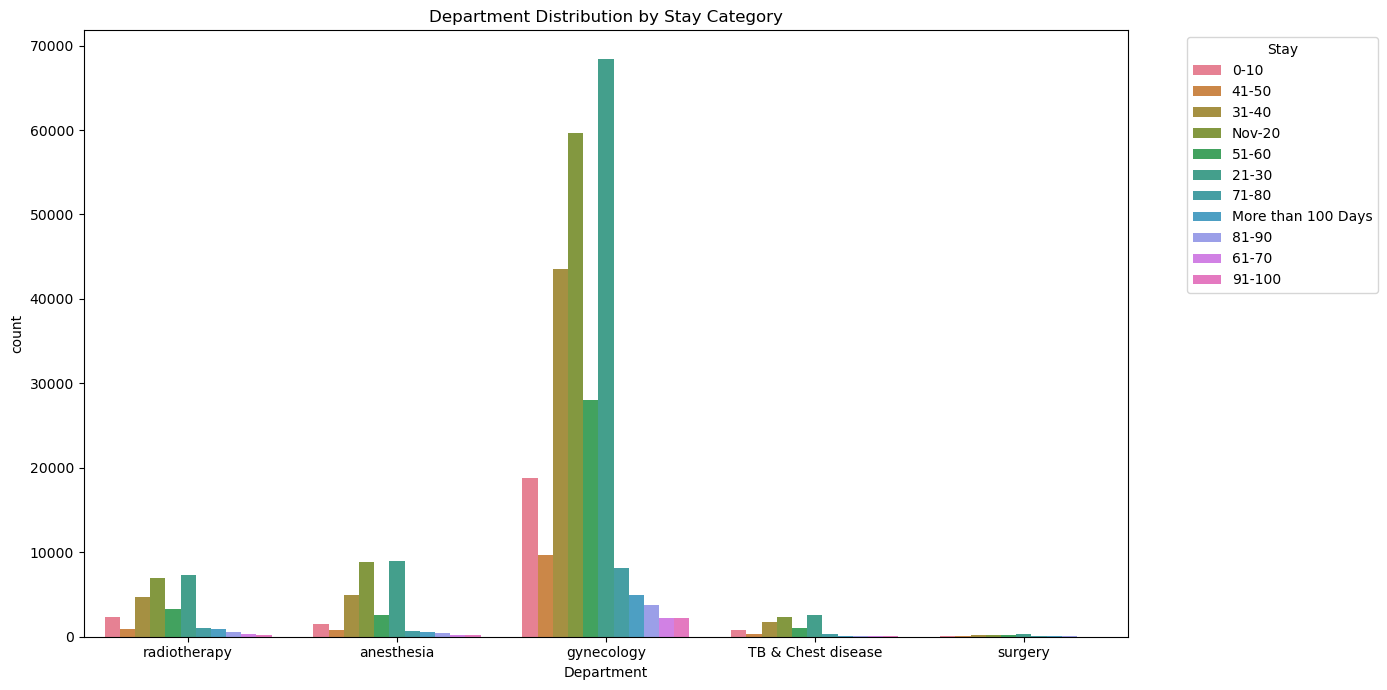

In [31]:

# 1. Boxplot of Admission Deposit by Stay Category
plt.figure(figsize=(12, 6))
sns.boxplot(x='Stay', y='Admission_Deposit', data=df) # You'll need to import seaborn as sns
plt.title('Admission Deposit by Stay Category')
plt.xticks(rotation=45)
plt.show()

# 2. Countplot of Department by Stay Category
plt.figure(figsize=(14, 7))
sns.countplot(x='Department', hue='Stay', data=df) # You'll need to import seaborn as sns
plt.title('Department Distribution by Stay Category')
plt.legend(title='Stay', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

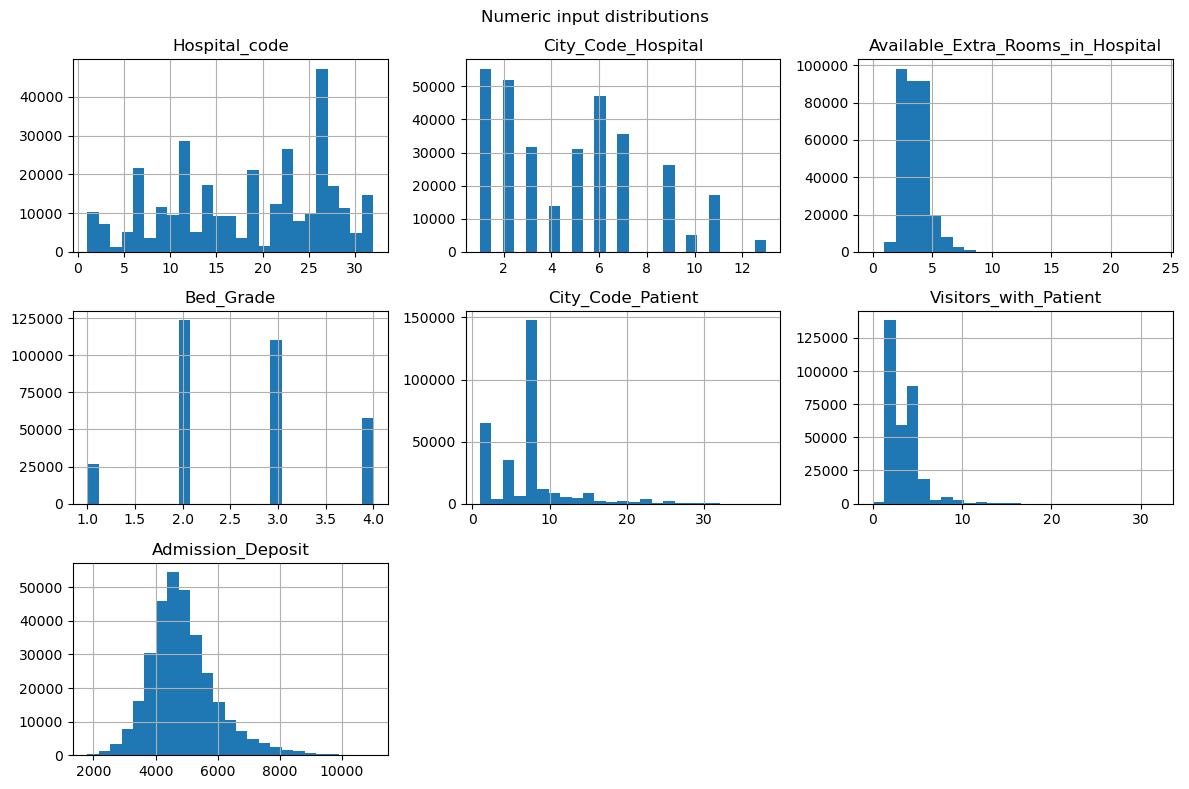

In [12]:
numeric_columns = df[feature_columns].select_dtypes(include="number").columns.tolist()
df[numeric_columns].hist(figsize=(12, 8), bins=25)
plt.suptitle("Numeric input distributions")
plt.tight_layout()
plt.show()

## step 5 :Data cleaning

In [13]:
model_df = df.drop_duplicates().copy()
X = model_df[feature_columns].copy()
y = model_df[target].astype("string").copy()
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = [c for c in X.columns if c not in numeric_columns]
print("Rows after duplicate removal:", len(model_df))
print("Missing numeric values:", X[numeric_columns].isna().sum().sum())
print("Missing categorical values:", X[categorical_columns].isna().sum().sum())

Rows after duplicate removal: 318438
Missing numeric values: 4645
Missing categorical values: 0


## step 6:Base line model 

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline weighted F1:", round(f1_score(y_test, baseline_pred, average="weighted", zero_division=0), 4))

Baseline accuracy: 0.2747
Baseline weighted F1: 0.1184


## step 7 :Model building 

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_columns),
        ("categorical", categorical_pipe, categorical_columns)
    ])

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", make_preprocessor(True)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DecisionTreeClassifier(max_depth=15, min_samples_leaf=20,
            class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=100, max_depth=20,
            min_samples_leaf=10, class_weight="balanced_subsample",
            n_jobs=-1, random_state=42))
    ])
}
model_predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    model_predictions[name] = model.predict(X_test)
    print("Finished:", name)

Finished: Logistic Regression
Finished: Decision Tree
Finished: Random Forest


## step 8:Model comparison 

In [16]:
comparison = [{
    "Model": name,
    "Accuracy": accuracy_score(y_test, pred),
    "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0)
} for name, pred in model_predictions.items()]
comparison.append({
    "Model": "Most-frequent baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Weighted F1": f1_score(y_test, baseline_pred, average="weighted", zero_division=0)
})
comparison = pd.DataFrame(comparison).sort_values("Weighted F1", ascending=False).reset_index(drop=True)
display(comparison)
model_rows = comparison[comparison["Model"] != "Most-frequent baseline"]
best_model_name = model_rows.loc[model_rows["Weighted F1"].idxmax(), "Model"]
print("Top tested model by weighted F1:", best_model_name)

,Model,Accuracy,Weighted F1
0,Random Forest,0.314957,0.317721
1,Logistic Regression,0.251649,0.267759
2,Decision Tree,0.236481,0.257838
3,Most-frequent baseline,0.274746,0.118432


Top tested model by weighted F1: Random Forest


## step 9 :Evaluation 

                    precision    recall  f1-score   support

              0-10       0.22      0.57      0.31      4721
             21-30       0.48      0.35      0.40     17498
             31-40       0.46      0.08      0.13     11032
             41-50       0.08      0.23      0.12      2349
             51-60       0.37      0.33      0.35      7004
             61-70       0.04      0.11      0.05       549
             71-80       0.16      0.24      0.19      2051
             81-90       0.20      0.59      0.30       967
            91-100       0.07      0.18      0.10       553
More than 100 Days       0.36      0.50      0.42      1336
            Nov-20       0.44      0.36      0.40     15628

          accuracy                           0.31     63688
         macro avg       0.26      0.32      0.25     63688
      weighted avg       0.39      0.31      0.32     63688



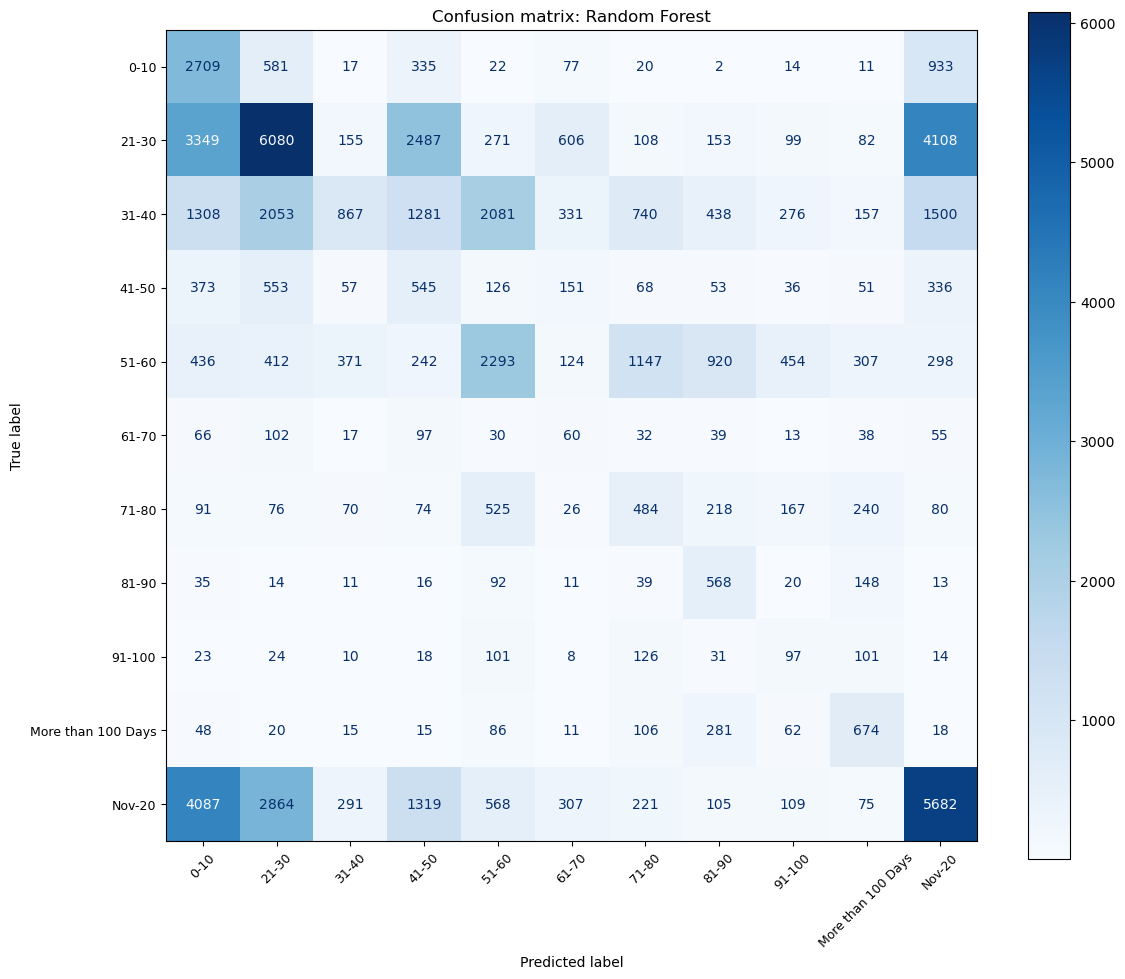

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best_prediction = model_predictions[best_model_name]
print(classification_report(y_test, best_prediction, zero_division=0))
labels = sorted(y.unique().dropna().tolist())
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_prediction, labels=labels, xticks_rotation=45,
    cmap="Blues", values_format="d", ax=ax
)
ax.tick_params(axis="both", labelsize=9)
ax.set_title("Confusion matrix: " + best_model_name)
fig.tight_layout()
plt.show()


## Limitations  and challenges:

- `Stay` contains ranges rather than exact days, so exact-day regression cannot be trained from this file.
- Category counts are uneven; overall scores may hide weak results for rare categories.
- `Bed_Grade` and `City_Code_Patient` have missing values; the pipeline imputes them.
- Identifier columns are excluded, but a random split can still put the same patient in train and test, making scores optimistic for new patients.
- The CSV does not define the meanings of its hospital, city, ward, and severity codes.
- This data alone cannot show that predictions are safe, fair, current, or useful for clinical decisions

## Step 11 — Conclusion

This project analyzed hospital admission records and compared three machine learning models to predict a patient’s recorded length-of-stay category. The dataset contains stay ranges, such as 0-10 and 21-30, rather than the exact number of days. The models can therefore predict a category, but not an exact stay length.
The comparison and category-level evaluation show how well each model performed on the test data. The best-scoring model is a candidate for further validation, but the results alone do not show that it is ready for use in a hospital. Further testing with new patient data is needed.